# List 1: PyTorch & Training Fundamentals

Labs: Mon 5 Oct, Mon 12 Oct 2026 · Due: Sun 18 Oct 2026, 23:59 · 1 point

- For each task, show the requested numbers or plots and explain them in two to four sentences. The list is graded as a whole, in steps of 0.25, by how complete, correct and well explained your solution is.
- Data, code structure and names are up to you; defaults are given for when you have no preference. Keep the signatures of the four given functions, because later lists reuse them (check them with Materials, Appendix A).
- Background and the PyTorch functions you need for Task X.Y are in Materials X.Y.
- Submit this notebook run from top to bottom with outputs, or Python scripts with a PDF report of at most four pages (results and explanations per task). Late: −10% per day, 0 after 5 days.
- Individual work. Name the AI tools you used at the top of your solution.

In [52]:
import torch
import torch.nn.functional as F
from torch import nn
from torch.utils.data import DataLoader
import numpy as np

## Lab 1

### 1.1 Tensors

- Write down the expected shapes of five operations (covering reshape, transpose, `@`, `*` and broadcasting, one of them a broadcast that fails), then run them. Explain the failure.
- Show a case where `view` fails and `reshape` works, and explain it with strides.
- Show a computation that `float32` gets wrong and `float64` gets right.
- Convert an array from NumPy to PyTorch and back. Show which conversions share memory, and which dtype each library uses by default.

In [24]:
A = torch.arange(0, 8)
print(A)
print(A.shape)

print("------------------------------------------------------------------------------")

B = A.reshape(2,4)
print("Expected shape is (2,4)")
print(B)
print(B.shape)

print("------------------------------------------------------------------------------")

C = B.t()
print("Expected shape is (4,2)")
print(C)
print(C.shape)

print("------------------------------------------------------------------------------")

D = B @ C
print("Expected shape is (2,2)")
print(D)
print(D.shape)

print("------------------------------------------------------------------------------")

E = B[:,0:2] * C[0:2,:]
print("Expected shape is (2,2)")
print(E)
print(E.shape)

print("------------------------------------------------------------------------------")

x = torch.zeros(3, 1, 7)
y = torch.zeros(5, 1)
print("Expected shape is (3,5,7)")
print((x + y).shape)

print("------------------------------------------------------------------------------")

X = torch.zeros(2, 3, 4)
Y = torch.zeros(5, 3)
print("Expected to fail: in some dimension the sizes differ and neither is 1.")
try:
    print((X + Y).shape)
except RuntimeError as e:
    print("Broadcasting failed as expected:", e)


tensor([0, 1, 2, 3, 4, 5, 6, 7])
torch.Size([8])
------------------------------------------------------------------------------
Expected shape is (2,4)
tensor([[0, 1, 2, 3],
        [4, 5, 6, 7]])
torch.Size([2, 4])
------------------------------------------------------------------------------
Expected shape is (4,2)
tensor([[0, 4],
        [1, 5],
        [2, 6],
        [3, 7]])
torch.Size([4, 2])
------------------------------------------------------------------------------
Expected shape is (2,2)
tensor([[ 14,  38],
        [ 38, 126]])
torch.Size([2, 2])
------------------------------------------------------------------------------
Expected shape is (2,2)
tensor([[ 0,  4],
        [ 4, 25]])
torch.Size([2, 2])
------------------------------------------------------------------------------
Expected shape is (3,5,7)
torch.Size([3, 5, 7])
------------------------------------------------------------------------------
Expected to fail: in some dimension the sizes differ and neither is 1

In [32]:
X = torch.arange(6).reshape(2, 3)
T = X.t()                 
try:
    print(T.view(6))      
except RuntimeError as e:
    print("Operation view failed:", e, sep = "\n")

print(T.reshape(6))

print(T.is_contiguous())  

Operation view failed:
view size is not compatible with input tensor's size and stride (at least one dimension spans across two contiguous subspaces). Use .reshape(...) instead.
tensor([0, 3, 1, 4, 2, 5])
False


`view(6)` fails because the required memory jumps (+3, −2, +3, …) are not constant, so no single stride can describe T as a 1D tensor without copying. However `reshape(6)` do not fail because it copies the tensor.

In [40]:
for dtype in (torch.float32, torch.float64):
    big = torch.tensor(1e8, dtype=dtype)
    result = (big + 1) - big
    print(dtype, result.item())

torch.float32 0.0
torch.float64 1.0


In [ ]:
# ---------- Default dtypes ----------
print(np.array([1.0, 2.0]).dtype)      # float64
print(np.array([1, 2]).dtype)          # int64 
print(torch.tensor([1.0, 2.0]).dtype)  # torch.float32
print(torch.tensor([1, 2]).dtype)      # torch.int64

# ---------- NumPy -> PyTorch ----------
a = np.array([1.0, 2.0, 3.0])          # float64

t_from = torch.from_numpy(a)           # shares memory, keeps float64
t_as   = torch.as_tensor(a)            # shares memory (dtype and device match)
t_new  = torch.tensor(a)               # always copies, still float64
t_f32  = torch.as_tensor(a, dtype=torch.float32)  # copies (dtype changes)

a[0] = 100.0
print(t_from)   # tensor([100., 2., 3.], dtype=torch.float64)  shared
print(t_as)     # tensor([100., 2., 3.], dtype=torch.float64)  shared
print(t_new)    # tensor([1., 2., 3.], dtype=torch.float64)    copy
print(t_f32)    # tensor([1., 2., 3.])                         copy, float32

# ---------- PyTorch -> NumPy ----------
t = torch.tensor([1.0, 2.0, 3.0])      # float32

n_view  = t.numpy()                    # shares memory, keeps float32
n_as    = np.asarray(t)                # shares memory
n_copy  = np.array(t)                  # copies

t[0] = 100.0
print(n_view)   # [100.   2.   3.]  shared
print(n_as)     # [100.   2.   3.]  shared
print(n_copy)   # [1. 2. 3.]        copy

# Checking without modifying anything:
print(np.shares_memory(t.numpy(), n_view))   # True
print(np.shares_memory(t.numpy(), n_copy))   # False

float64
int64
torch.float32
torch.int64
tensor([100.,   2.,   3.], dtype=torch.float64)
tensor([100.,   2.,   3.], dtype=torch.float64)
tensor([1., 2., 3.], dtype=torch.float64)
tensor([1., 2., 3.])
[100.   2.   3.]
[100.   2.   3.]
[1. 2. 3.]
True
False


C:\Users\Komputer\AppData\Local\Temp\ipykernel_5732\1430497149.py:26: DeprecationWarning: __array__ implementation doesn't accept a copy keyword, so passing copy=False failed. __array__ must implement 'dtype' and 'copy' keyword arguments. To learn more, see the migration guide https://numpy.org/devdocs/numpy_2_0_migration_guide.html#adapting-to-changes-in-the-copy-keyword
  n_copy  = np.array(t)                  # copies


### 1.2 Autograd and a gradient check

One-feature logistic regression with binary cross-entropy: $L = -[\,y \log a + (1-y)\log(1-a)\,]$, $a = \sigma(w_1 x_1 + b)$.

- Compute $\partial L/\partial w_1$ and $\partial L/\partial b$ analytically, with autograd and with central finite differences, in `float64`, and check that they match. Reference: for $x_1 = 1.1$, $w_1 = 2.2$, $b = 0$, $y = 1$, $L \approx 0.0852$ and the gradients are $\approx -0.0898$ and $-0.0817$.
- Plot the error of the finite-difference $\partial L/\partial w_1$ (against the analytic value) for $h = 10^{-1}, \dots, 10^{-12}$ on log–log axes, in `float32` and `float64`. Explain the shape of the curves.
- Call `backward()` on two freshly built losses without resetting `.grad`. Show and explain what happens.

In [42]:
def bce_loss(w1, b, x1, y):
    a = torch.sigmoid(w1 * x1 + b)
    return -(y * torch.log(a) + (1 - y) * torch.log(1 - a))

x1, y = 1.1, 1.0
w1 = torch.tensor(2.2, dtype=torch.float64, requires_grad=True)
b = torch.tensor(0.0, dtype=torch.float64, requires_grad=True)

# ---------- Analytic: dL/dz = a - y, so dL/dw1 = (a - y) x1, dL/db = a - y ----------
with torch.no_grad():
    a = torch.sigmoid(w1 * x1 + b)
    grad_w_analytic = ((a - y) * x1).item()
    grad_b_analytic = (a - y).item()

# ---------- Autograd ----------
L = bce_loss(w1, b, x1, y)
L.backward()
grad_w_autograd, grad_b_autograd = w1.grad.item(), b.grad.item()

# ---------- Central finite differences ----------
h = 1e-6
with torch.no_grad():
    grad_w_fd = ((bce_loss(w1 + h, b, x1, y) - bce_loss(w1 - h, b, x1, y)) / (2 * h)).item()
    grad_b_fd = ((bce_loss(w1, b + h, x1, y) - bce_loss(w1, b - h, x1, y)) / (2 * h)).item()

print(f"L = {L.item():.6f}")
print(f"{'':10s}{'dL/dw1':>16s}{'dL/db':>16s}")
for name, gw, gb in [("analytic", grad_w_analytic, grad_b_analytic),
                     ("autograd", grad_w_autograd, grad_b_autograd),
                     ("finite d.", grad_w_fd, grad_b_fd)]:
    print(f"{name:10s}{gw:16.10f}{gb:16.10f}")

analytic = torch.tensor([grad_w_analytic, grad_b_analytic], dtype=torch.float64)
print("autograd  == analytic:", torch.allclose(torch.tensor([grad_w_autograd, grad_b_autograd], dtype=torch.float64), analytic))
print("finite d. ~= analytic:", torch.allclose(torch.tensor([grad_w_fd, grad_b_fd], dtype=torch.float64), analytic, atol=1e-8))

L = 0.085188
                    dL/dw1           dL/db
analytic     -0.0898262810   -0.0816602555
autograd     -0.0898262810   -0.0816602555
finite d.    -0.0898262810   -0.0816602555
autograd  == analytic: True
finite d. ~= analytic: True


With $z = w_1 x_1 + b$ and $\sigma'(z) = a(1-a)$, the chain rule gives $\partial L/\partial z = a - y$, so $\partial L/\partial w_1 = (a-y)\,x_1$ and $\partial L/\partial b = a - y$. All three methods give $L \approx 0.0852$, $\partial L/\partial w_1 \approx -0.0898$ and $\partial L/\partial b \approx -0.0817$, matching the reference. Autograd agrees with the analytic formula to machine precision, and the central finite differences (with $h = 10^{-6}$) agree to about $10^{-10}$.

torch.float32 ['1.4e-04', '2.4e-06', '3.2e-05', '6.1e-04', '4.4e-03', '5.6e-02', '9.0e-02', '9.0e-02', '9.0e-02', '9.0e-02', '9.0e-02', '9.0e-02']
torch.float64 ['1.4e-04', '1.4e-06', '1.4e-08', '1.4e-10', '4.3e-12', '1.1e-11', '5.8e-11', '2.6e-09', '3.0e-08', '2.0e-07', '1.6e-06', '2.3e-06']


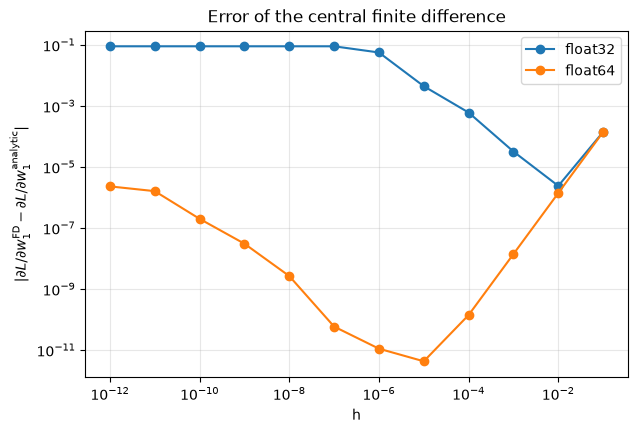

In [43]:
import matplotlib.pyplot as plt

hs = [10.0 ** -k for k in range(1, 13)]

plt.figure(figsize=(7, 4.5))
for dtype in (torch.float32, torch.float64):
    w1_d = torch.tensor(2.2, dtype=dtype)
    b_d = torch.tensor(0.0, dtype=dtype)
    errors = []
    for h in hs:
        fd = (bce_loss(w1_d + h, b_d, x1, y) - bce_loss(w1_d - h, b_d, x1, y)) / (2 * h)
        errors.append(abs(fd.item() - grad_w_analytic))
    print(dtype, ["%.1e" % e for e in errors])
    plt.loglog(hs, errors, "o-", label=str(dtype).replace("torch.", ""))

plt.xlabel("h")
plt.ylabel(r"$|\partial L/\partial w_1^{\mathrm{FD}} - \partial L/\partial w_1^{\mathrm{analytic}}|$")
plt.title("Error of the central finite difference")
plt.grid(True, which="both", alpha=0.3)
plt.legend()
plt.show()

The total error is truncation error plus rounding error. For large $h$ the truncation error of the central difference dominates, which is $O(h^2)$, so the curve falls with slope 2 on the log–log plot (one decade of $h$ gives two decades of error). For small $h$ the rounding error dominates.

In [46]:
w1 = torch.tensor(2.2, dtype=torch.float64, requires_grad=True)
b = torch.tensor(0.0, dtype=torch.float64, requires_grad=True)

bce_loss(w1, b, x1, y).backward()
print("after 1st backward:      dL/dw1 =", w1.grad.item(), " dL/db =", b.grad.item())

bce_loss(w1, b, x1, y).backward()   # second, freshly built loss, .grad not reset
print("after 2nd backward:      dL/dw1 =", w1.grad.item(), " dL/db =", b.grad.item())

w1.grad = None
b.grad = None
bce_loss(w1, b, x1, y).backward()
print("after reset + backward:  dL/dw1 =", w1.grad.item(), " dL/db =", b.grad.item())


after 1st backward:      dL/dw1 = -0.08982628100775408  dL/db = -0.08166025546159461
after 2nd backward:      dL/dw1 = -0.17965256201550817  dL/db = -0.16332051092318922
after reset + backward:  dL/dw1 = -0.08982628100775408  dL/db = -0.08166025546159461


The gradients are accumulated: `backward()` adds the new gradient to whatever is already stored in `.grad` instead of overwriting it. After the second call `.grad` holds exactly twice the true gradient, so an optimizer step would use a wrong (doubled) gradient. This is why the training loop calls `optimizer.zero_grad()` (or sets `.grad = None`) before every `backward()`. Accumulation is deliberate: it lets you sum gradients over several mini-batches before one update.

### 1.3 Linear regression

Default data: $N = 200$, $d = 3$, $\mathbf{x} \sim \mathcal{N}(\mathbf{0}, \operatorname{diag}(1, 4, 0.25))$, $y = \mathbf{w}^{\ast\top}\mathbf{x} + b^\ast + 0.1\,\varepsilon$ with $\mathbf{w}^\ast, b^\ast$ of your choice.

- Minimise the mean squared error by least squares, and by full-batch gradient descent twice: in NumPy with the gradient derived by hand, and in PyTorch with autograd and `torch.optim.SGD`. Compare the three solutions.
- Find the largest learning rate for which the loss still decreases over 300 steps, experimentally (two significant digits) and from the Hessian. Compare.

In [47]:
# ---------- Data ----------
rng = np.random.default_rng(0)
N, d = 200, 3
w_true = np.array([2.0, -1.0, 0.5])
b_true = 1.0
X = rng.normal(size=(N, d)) * np.sqrt([1.0, 4.0, 0.25])   # cov = diag(1, 4, 0.25)
y = X @ w_true + b_true + 0.1 * rng.normal(size=N)

def mse(w, b):
    return np.mean((X @ w + b - y) ** 2)

# ---------- 1) Least squares ----------
X_aug = np.hstack([X, np.ones((N, 1))])                    # column of ones for the bias
theta_ls, *_ = np.linalg.lstsq(X_aug, y, rcond=None)
w_ls, b_ls = theta_ls[:d], theta_ls[d]

# ---------- 2) NumPy GD with a hand-derived gradient ----------
# L = 1/N sum r_i^2, r = Xw + b - y  =>  dL/dw = 2/N X^T r,  dL/db = 2/N sum r_i
def gd_numpy(lr, steps):
    w, b = np.zeros(d), 0.0
    losses = [mse(w, b)]
    for _ in range(steps):
        r = X @ w + b - y
        w = w - lr * (2 / N) * X.T @ r
        b = b - lr * (2 / N) * r.sum()
        losses.append(mse(w, b))
    return w, b, losses

lr, steps = 0.1, 1000
w_np, b_np, _ = gd_numpy(lr, steps)

# ---------- 3) PyTorch: autograd + torch.optim.SGD ----------
Xt, yt = torch.tensor(X), torch.tensor(y)
model = nn.Linear(d, 1, dtype=torch.float64)
nn.init.zeros_(model.weight)
nn.init.zeros_(model.bias)
opt = torch.optim.SGD(model.parameters(), lr=lr)
for _ in range(steps):
    opt.zero_grad()
    loss = ((model(Xt).squeeze(1) - yt) ** 2).mean()
    loss.backward()
    opt.step()
w_pt = model.weight.detach().numpy().ravel()
b_pt = model.bias.item()

# ---------- Comparison ----------
print(f"{'':16s}{'w1':>10s}{'w2':>10s}{'w3':>10s}{'b':>10s}{'MSE':>12s}")
for name, w, b in [("true", w_true, b_true), ("least squares", w_ls, b_ls),
                   ("NumPy GD", w_np, b_np), ("PyTorch SGD", w_pt, b_pt)]:
    print(f"{name:16s}" + "".join(f"{v:10.5f}" for v in w) + f"{b:10.5f}{mse(w, b):12.7f}")

print("max |NumPy GD - LS|    =", np.abs(np.append(w_np, b_np) - theta_ls).max())
print("max |PyTorch  - LS|    =", np.abs(np.append(w_pt, b_pt) - theta_ls).max())
print("max |PyTorch  - NumPy| =", np.abs(np.append(w_pt, b_pt) - np.append(w_np, b_np)).max())

                        w1        w2        w3         b         MSE
true               2.00000  -1.00000   0.50000   1.00000   0.0102271
least squares      1.99100  -1.00481   0.51061   0.99639   0.0100016
NumPy GD           1.99100  -1.00481   0.51061   0.99639   0.0100016
PyTorch SGD        1.99100  -1.00481   0.51061   0.99639   0.0100016
max |NumPy GD - LS|    = 1.9984014443252818e-15
max |PyTorch  - LS|    = 1.887379141862766e-15
max |PyTorch  - NumPy| = 1.1102230246251565e-16


Data: $\mathbf{w}^\ast = (2, -1, 0.5)$, $b^\ast = 1$, seed 0. All three solutions agree to about $10^{-15}$: the MSE is a convex quadratic with a unique minimum, least squares finds it in closed form, and gradient descent (1000 steps, $\eta = 0.1$) converges to it. The NumPy and PyTorch runs perform identical updates (same initialisation, same gradient $\tfrac{2}{N}\tilde X^\top \mathbf r$, plain SGD without momentum on the full batch), so they coincide to machine precision. The estimate differs from $(\mathbf{w}^\ast, b^\ast)$ by about $0.01$ because of the noise $0.1\,\varepsilon$, and its MSE ($\approx 0.0100$) is slightly *below* that of the true parameters, since it is fitted to this particular noisy sample.

Hessian eigenvalues: [0.4688 1.9054 2.1599 7.9939]
theory:       lr_max = 2 / lambda_max = 0.2502
experimental: lr_max = 0.2503  (~0.25)


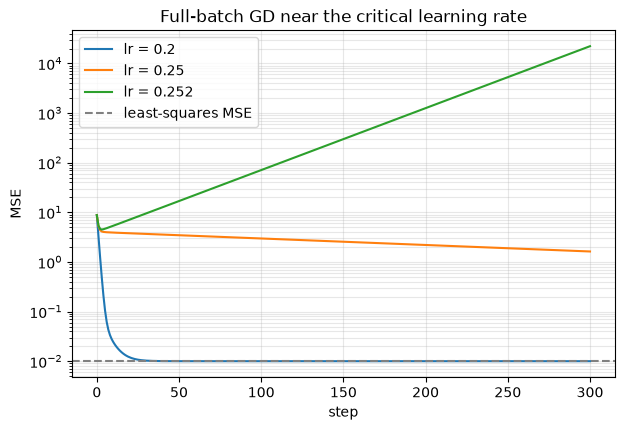

In [48]:
# ---------- From the Hessian ----------
H = (2 / N) * X_aug.T @ X_aug          # Hessian of the MSE w.r.t. (w, b), constant
eig = np.linalg.eigvalsh(H)
lr_theory = 2 / eig.max()
print("Hessian eigenvalues:", np.round(eig, 4))
print(f"theory:       lr_max = 2 / lambda_max = {lr_theory:.4f}")

# ---------- Experimentally: bisection ----------
def decreases(lr, steps=300):
    _, _, losses = gd_numpy(lr, steps)
    return losses[-1] < losses[0]

lo, hi = 0.01, 1.0                     # decreases(lo) = True, decreases(hi) = False
while hi - lo > 1e-5:
    mid = (lo + hi) / 2
    lo, hi = (mid, hi) if decreases(mid) else (lo, mid)
print(f"experimental: lr_max = {lo:.4f}  (~{lo:.2g})")

# ---------- Loss curves around the threshold ----------
plt.figure(figsize=(7, 4.5))
for lr_ in (0.20, 0.25, 0.252):
    plt.semilogy(gd_numpy(lr_, 300)[2], label=f"lr = {lr_}")
plt.axhline(mse(w_ls, b_ls), color="gray", ls="--", label="least-squares MSE")
plt.xlabel("step")
plt.ylabel("MSE")
plt.title("Full-batch GD near the critical learning rate")
plt.grid(True, which="both", alpha=0.3)
plt.legend()
plt.show()

The MSE is a quadratic in $\boldsymbol\theta = (\mathbf{w}, b)$ with constant Hessian $H = \tfrac{2}{N}\tilde X^\top \tilde X$ ($\tilde X$ = $X$ with a column of ones). Gradient descent multiplies the error along each eigenvector of $H$ by $(1 - \eta\lambda_i)$ every step, so it converges iff $|1 - \eta\lambda_i| < 1$ for all $i$, i.e. $\eta < 2/\lambda_{\max}$. Here $\lambda_{\max} \approx 7.99$ (roughly $2\cdot\operatorname{Var}(x_2) = 8$, the direction with the largest variance), so $\eta_{\max} \approx 0.25$. The bisection (criterion: loss after 300 steps lower than at the start) gives the same value to two significant digits, $0.25$; it lands slightly *above* $2/\lambda_{\max}$, because just past the threshold the unstable mode grows so slowly ($|1-\eta\lambda_{\max}|$ barely above 1) that 300 steps are not enough to push the loss back above its initial value. The plot shows this: at $\eta = 0.20$ the loss converges quickly, at $0.25$ it still converges but slowly (factor $\approx 0.998$ per step in the top mode), and at $0.252$ it explodes.

### 1.4 A multilayer network

- Implement `count_parameters` and an MLP as an `nn.Module` built from a list of layer sizes, with ReLU between layers. For sizes `[50, 30, 20, 3]`, check the count (2213) against a sum written by hand.
- Implement a softmax without `torch.softmax` that stays finite for the logits `[1000., 1001., 999.]`.

In [49]:
def count_parameters(model: nn.Module, trainable_only: bool = True) -> int:
    """Number of (trainable) scalar parameters of `model`."""
    return sum(p.numel() for p in model.parameters() if p.requires_grad or not trainable_only)

In [50]:
class MLP(nn.Module):
    """Linear layers of the given sizes with ReLU between them (none after the last)."""

    def __init__(self, sizes: list[int]):
        super().__init__()
        layers = []
        for d_in, d_out in zip(sizes[:-1], sizes[1:]):
            layers += [nn.Linear(d_in, d_out), nn.ReLU()]
        self.net = nn.Sequential(*layers[:-1])   # drop the ReLU after the output layer

    def forward(self, x):
        return self.net(x)


mlp = MLP([50, 30, 20, 3])
print(mlp)

by_hand = (50 * 30 + 30) + (30 * 20 + 20) + (20 * 3 + 3)   # weights + biases of each layer
print("count_parameters:", count_parameters(mlp))
print("by hand:         ", by_hand)
assert count_parameters(mlp) == by_hand == 2213

mlp.net[0].weight.requires_grad_(False)
print("first weight frozen -> trainable:", count_parameters(mlp),
      " all:", count_parameters(mlp, trainable_only=False))
mlp.net[0].weight.requires_grad_(True)

print("output shape for a batch of 4:", mlp(torch.randn(4, 50)).shape)

MLP(
  (net): Sequential(
    (0): Linear(in_features=50, out_features=30, bias=True)
    (1): ReLU()
    (2): Linear(in_features=30, out_features=20, bias=True)
    (3): ReLU()
    (4): Linear(in_features=20, out_features=3, bias=True)
  )
)
count_parameters: 2213
by hand:          2213
first weight frozen -> trainable: 713  all: 2213
output shape for a batch of 4: torch.Size([4, 3])


The MLP is built from consecutive pairs of sizes: `[50, 30, 20, 3]` gives three `nn.Linear` layers with ReLU between them and no activation after the last one (its outputs are logits). An `nn.Linear(d_in, d_out)` has a $d_{\text{out}} \times d_{\text{in}}$ weight and $d_{\text{out}}$ biases, so the count is $(50\cdot30 + 30) + (30\cdot20 + 20) + (20\cdot3 + 3) = 1530 + 620 + 63 = 2213$, matching `count_parameters`. ReLU has no parameters. Freezing the first weight matrix (1500 entries) leaves 713 trainable parameters, while `trainable_only=False` still counts all 2213.

In [51]:
def softmax(z: torch.Tensor, dim: int = -1) -> torch.Tensor:
    z = z - z.max(dim=dim, keepdim=True).values   # shift so the largest logit is 0
    e = torch.exp(z)
    return e / e.sum(dim=dim, keepdim=True)

logits = torch.tensor([1000.0, 1001.0, 999.0])
naive = torch.exp(logits) / torch.exp(logits).sum()
print("naive:        ", naive)
print("stable:       ", softmax(logits))
print("torch.softmax:", torch.softmax(logits, dim=-1))
print("sum:", softmax(logits).sum().item())

assert torch.allclose(softmax(logits), torch.softmax(logits, dim=-1))
Z = torch.randn(5, 7) * 100                       # also works row-wise on a batch
assert torch.allclose(softmax(Z), torch.softmax(Z, dim=-1))

naive:         tensor([nan, nan, nan])
stable:        tensor([0.2447, 0.6652, 0.0900])
torch.softmax: tensor([0.2447, 0.6652, 0.0900])
sum: 1.0


The naive formula computes $e^{1000}$, which overflows to `inf` (the largest `float32` is $\approx 3.4\cdot10^{38} \approx e^{88.7}$), and `inf / inf` gives `nan`. Softmax is invariant to adding a constant to all logits, $\operatorname{softmax}(\mathbf z - c)_i = e^{z_i - c}/\sum_j e^{z_j - c} = \operatorname{softmax}(\mathbf z)_i$, so we subtract $c = \max_j z_j$. Then every exponent is $\le 0$, so nothing overflows, and the largest term is exactly $e^0 = 1$, so the denominator is $\ge 1$ and cannot underflow to 0. The result $(0.2447, 0.6652, 0.0900)$ equals `torch.softmax` and is the same as for the logits $(1, 2, 0)$.

## Lab 2

### 2.1 `Dataset` and `DataLoader`

Default data: four classes in the plane, 150 points each, centres $(\pm 2, \pm 2)$, $\mathbf{x} = \boldsymbol\mu_c + 0.9\,\boldsymbol\epsilon$.

- Write a `Dataset`, split it 60/20/20 with a fixed seed, and build the three `DataLoader`s. Explain why only the training loader is shuffled.

sizes: 360 120 120
one batch: torch.Size([32, 2]) torch.float32 torch.Size([32]) torch.int64
class counts (train / val / test): [[80, 96, 86, 98], [32, 26, 35, 27], [38, 28, 29, 25]]


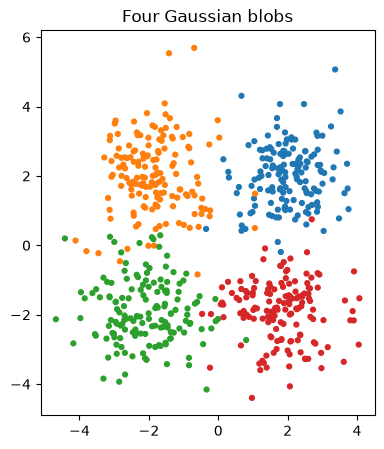

In [53]:
import math
import os
from pathlib import Path
from torch.utils.data import Dataset, TensorDataset, random_split


class Blobs(Dataset):
    """Four Gaussian classes in the plane: x = mu_c + sigma * eps."""

    def __init__(self, n_per_class: int = 150, sigma: float = 0.9, seed: int = 0):
        g = torch.Generator().manual_seed(seed)
        centres = torch.tensor([[2.0, 2.0], [-2.0, 2.0], [-2.0, -2.0], [2.0, -2.0]])
        self.y = torch.arange(4).repeat_interleave(n_per_class)             # int64 labels 0..3
        self.x = centres[self.y] + sigma * torch.randn(len(self.y), 2, generator=g)

    def __len__(self):
        return len(self.y)

    def __getitem__(self, i):
        return self.x[i], self.y[i]


blobs = Blobs()
train_ds, val_ds, test_ds = random_split(blobs, [0.6, 0.2, 0.2], generator=torch.Generator().manual_seed(0))
print("sizes:", len(train_ds), len(val_ds), len(test_ds))

torch.manual_seed(0)
train_loader = DataLoader(train_ds, batch_size=32, shuffle=True)
val_loader = DataLoader(val_ds, batch_size=32)
test_loader = DataLoader(test_ds, batch_size=32)

xb, yb = next(iter(train_loader))
print("one batch:", xb.shape, xb.dtype, yb.shape, yb.dtype)
print("class counts (train / val / test):",
      [torch.bincount(blobs.y[s.indices], minlength=4).tolist() for s in (train_ds, val_ds, test_ds)])

plt.figure(figsize=(5, 5))
plt.scatter(blobs.x[:, 0], blobs.x[:, 1], c=blobs.y, cmap="tab10", vmax=9, s=12)
plt.gca().set_aspect("equal")
plt.title("Four Gaussian blobs")
plt.show()

`Blobs` generates the 600 points once (fixed seed) and `__getitem__` returns one `(features, label)` pair; the `DataLoader` stacks them into batches of shape $(32, 2)$ and $(32,)$ with `int64` labels. `random_split` with a seeded generator gives the same 360/120/120 split on every run. Only the training loader is shuffled: SGD assumes each mini-batch is a random sample, so a fresh order every epoch keeps the gradient estimates unbiased and prevents the model from seeing the same sequence of batches (e.g. sorted by class, as the data were generated) every time. Validation and test loaders are only used to compute averages over the whole set, which do not depend on the order, so shuffling them would only make runs harder to compare.

### 2.2 The training loop

- Implement `compute_loss`, `compute_accuracy` and `train`.
- Train your MLP once with SGD and once with Adam (default: sizes `[2, 30, 20, 4]`, batch size 32, 30 epochs) and plot both validation-loss curves. Pick the run with the lower final validation loss and report its test accuracy.
- Save its `state_dict`, load it into a new model, and show that it gives the same outputs.

In [54]:
def compute_loss(
    model: nn.Module, loader: DataLoader, device: torch.device | str = "cpu"
) -> float:
    """Mean cross-entropy over all predictions in `loader`.

    Logits may be (B, C) with targets (B,), or (B, T, C) with targets (B, T).
    """
    model.eval()
    total, n = 0.0, 0
    with torch.no_grad():
        for inputs, targets in loader:
            inputs, targets = inputs.to(device), targets.to(device)
            logits = model(inputs)
            total += F.cross_entropy(logits.reshape(-1, logits.shape[-1]), targets.reshape(-1),
                                     reduction="sum").item()
            n += targets.numel()
    return total / n

In [55]:
def compute_accuracy(
    model: nn.Module, loader: DataLoader, device: torch.device | str = "cpu"
) -> float:
    """Fraction of correct argmax predictions over all of `loader`."""
    model.eval()
    correct, n = 0, 0
    with torch.no_grad():
        for inputs, targets in loader:
            inputs, targets = inputs.to(device), targets.to(device)
            correct += (model(inputs).argmax(dim=-1) == targets).sum().item()
            n += targets.numel()
    return correct / n

In [56]:
def train(
    model: nn.Module,
    train_loader: DataLoader,
    val_loader: DataLoader,
    optimizer: torch.optim.Optimizer,
    num_epochs: int,
    device: torch.device | str = "cpu",
) -> dict[str, list[float]]:
    """Train with cross-entropy.

    Returns {"train_loss": [...], "val_loss": [...]}, one value per epoch.
    """
    history = {"train_loss": [], "val_loss": []}
    for epoch in range(num_epochs):
        model.train()
        batch_losses = []
        for inputs, targets in train_loader:
            inputs, targets = inputs.to(device), targets.to(device)
            logits = model(inputs)
            loss = F.cross_entropy(logits.reshape(-1, logits.shape[-1]), targets.reshape(-1))
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
            batch_losses.append(loss.item())
        history["train_loss"].append(sum(batch_losses) / len(batch_losses))
        history["val_loss"].append(compute_loss(model, val_loader, device))
    return history

In [57]:
# ---------- Contract check from Materials, Appendix A ----------
_g = torch.Generator().manual_seed(0)
_x = torch.randn(40, 3, generator=_g)
_y = (_x[:, 0] > 0).long()
_net = nn.Sequential(nn.Linear(3, 8), nn.ReLU(), nn.Linear(8, 2))
_loader = DataLoader(TensorDataset(_x, _y), batch_size=16)

assert count_parameters(_net) == 3 * 8 + 8 + 8 * 2 + 2
_net[0].weight.requires_grad_(False)
assert count_parameters(_net) == 26 and count_parameters(_net, trainable_only=False) == 50
_net[0].weight.requires_grad_(True)

_l16 = compute_loss(_net, _loader)
_l40 = compute_loss(_net, DataLoader(TensorDataset(_x, _y), batch_size=40))
assert isinstance(_l16, float) and abs(_l16 - _l40) < 1e-5, "the loss must not depend on the batch size"
assert 0.0 <= compute_accuracy(_net, _loader) <= 1.0

_seq = nn.Embedding(5, 5)
nn.init.zeros_(_seq.weight)
_tok = torch.randint(0, 5, (12, 7), generator=_g)
assert abs(compute_loss(_seq, DataLoader(TensorDataset(_tok, _tok), batch_size=4)) - math.log(5)) < 1e-5

_h = train(_net, _loader, _loader, torch.optim.Adam(_net.parameters(), lr=0.05), num_epochs=20)
assert set(_h) == {"train_loss", "val_loss"} and len(_h["train_loss"]) == len(_h["val_loss"]) == 20
assert _h["val_loss"][-1] < _h["val_loss"][0] and compute_accuracy(_net, _loader) > 0.9
print("Contract check passed: count_parameters, compute_loss, compute_accuracy, train")

Contract check passed: count_parameters, compute_loss, compute_accuracy, train


SGD (lr=0.05)   final train loss 0.1380  val loss 0.0594  val acc 0.975
Adam (lr=0.01)  final train loss 0.1324  val loss 0.0675  val acc 0.983


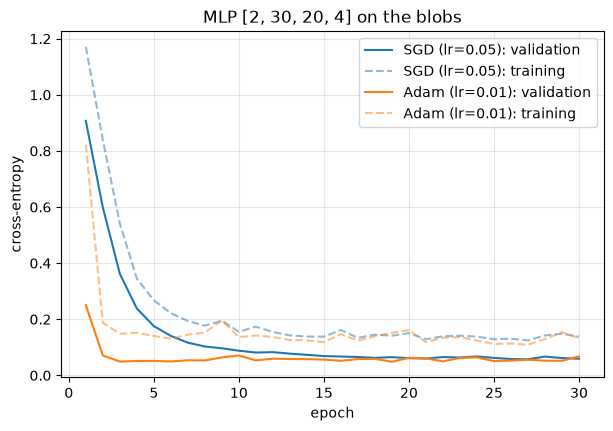

lower final validation loss: SGD (lr=0.05)
test accuracy = 0.967, test loss = 0.0765


In [58]:
histories, models = {}, {}
for name, make_opt in [("SGD (lr=0.05)", lambda p: torch.optim.SGD(p, lr=0.05)),
                       ("Adam (lr=0.01)", lambda p: torch.optim.Adam(p, lr=0.01))]:
    torch.manual_seed(0)                                   # same initial weights, same batch order
    model = MLP([2, 30, 20, 4])
    histories[name] = train(model, train_loader, val_loader, make_opt(model.parameters()), num_epochs=30)
    models[name] = model
    print(f"{name:15s} final train loss {histories[name]['train_loss'][-1]:.4f}  "
          f"val loss {histories[name]['val_loss'][-1]:.4f}  val acc {compute_accuracy(model, val_loader):.3f}")

plt.figure(figsize=(7, 4.5))
for name, h in histories.items():
    line, = plt.plot(range(1, 31), h["val_loss"], label=f"{name}: validation")
    plt.plot(range(1, 31), h["train_loss"], "--", color=line.get_color(), alpha=0.5, label=f"{name}: training")
plt.xlabel("epoch")
plt.ylabel("cross-entropy")
plt.title("MLP [2, 30, 20, 4] on the blobs")
plt.grid(alpha=0.3)
plt.legend()
plt.show()

best_name = min(histories, key=lambda k: histories[k]["val_loss"][-1])
best = models[best_name]
print(f"lower final validation loss: {best_name}")
print(f"test accuracy = {compute_accuracy(best, test_loader):.3f}, test loss = {compute_loss(best, test_loader):.4f}")

Both runs start from the same initial weights and the same batch order (`torch.manual_seed(0)` before each), so only the optimiser differs. Adam is much faster at the start: its per-parameter step size does not depend on the scale of the gradient, so its validation loss is already about 0.05 after 3 epochs, while SGD needs about 9 epochs to get below 0.1. After that Adam's validation loss creeps back up slightly (to 0.068 at epoch 30, a mild overfit to the 360 training points), while SGD is still slowly improving, so SGD ends with the lower final validation loss (0.059 vs 0.068) and is the run we keep; its **test accuracy is 96.7%**, close to the best possible, since the classes overlap a little. The training curves lie above the validation curves because they are means over the batches of each epoch and because this particular 120-point validation set happens to be slightly easier; the final difference between the two optimisers is small and could flip with another seed.

In [59]:
torch.save(best.state_dict(), "mlp_blobs.pth")
print({k: tuple(v.shape) for k, v in best.state_dict().items()})

restored = MLP([2, 30, 20, 4])                      # same architecture, new random weights
restored.load_state_dict(torch.load("mlp_blobs.pth", weights_only=True))

x_check = torch.randn(5, 2)
best.eval()
restored.eval()
with torch.no_grad():
    print(best(x_check))
    print(restored(x_check))
    print("identical outputs:", torch.equal(best(x_check), restored(x_check)))
print("test accuracy of the restored model:", compute_accuracy(restored, test_loader))

os.remove("mlp_blobs.pth")

{'net.0.weight': (30, 2), 'net.0.bias': (30,), 'net.2.weight': (20, 30), 'net.2.bias': (20,), 'net.4.weight': (4, 20), 'net.4.bias': (4,)}
tensor([[ 3.4207,  0.0858, -2.1047, -0.6575],
        [-2.0508,  2.8215,  0.9966, -2.7239],
        [ 1.1998,  0.9396, -1.1596, -0.5717],
        [ 0.0833, -0.5548, -0.4134,  1.7577],
        [ 0.3638,  1.5881, -0.7850, -1.0371]])
tensor([[ 3.4207,  0.0858, -2.1047, -0.6575],
        [-2.0508,  2.8215,  0.9966, -2.7239],
        [ 1.1998,  0.9396, -1.1596, -0.5717],
        [ 0.0833, -0.5548, -0.4134,  1.7577],
        [ 0.3638,  1.5881, -0.7850, -1.0371]])
identical outputs: True
test accuracy of the restored model: 0.9666666666666667


The `state_dict` contains only tensors (the weights and biases of the three linear layers), no code, so we first build the same architecture `MLP([2, 30, 20, 4])` with fresh random weights and then load the saved tensors into it. Both models give bit-identical logits (`torch.equal` is `True`) and the same test accuracy, so the whole learned state of the model is in the `state_dict`.

### 2.3 A count-based bigram model

Default text: `the-verdict.txt`. Tokens are characters; build the vocabulary from the whole text and use the last 10% for validation.

- Report training and validation perplexity for $\alpha \in \{0, 0.01, 0.1, 1, 10\}$ (report `inf` where it occurs) and explain both ends. On the default text, expect a validation perplexity of about 12 for $\alpha = 1$.
- Generate 200 characters from the $\alpha = 1$ model.

In [60]:
text = Path("the-verdict.txt").read_text(encoding="utf-8")
vocab = sorted(set(text))
V = len(vocab)
stoi = {ch: i for i, ch in enumerate(vocab)}
itos = {i: ch for ch, i in stoi.items()}
ids = torch.tensor([stoi[ch] for ch in text])
n_train = int(0.9 * len(ids))
train_ids, val_ids = ids[:n_train], ids[n_train:]          # validation = the last 10% of the text
print(f"{len(text)} characters, V = {V}, train {len(train_ids)}, val {len(val_ids)}")

counts = torch.bincount(train_ids[:-1] * V + train_ids[1:], minlength=V * V).view(V, V).double()

def bigram_table(alpha):
    c = counts + alpha
    return c / c.sum(dim=1, keepdim=True)

def perplexity(P, seq):
    p = P[seq[:-1], seq[1:]]                                 # probability of every actual pair
    return math.exp(-torch.log(p).mean().item())

print(f"{'alpha':>6s}{'train PPL':>12s}{'val PPL':>12s}")
for alpha in [0, 0.01, 0.1, 1, 10]:
    P = bigram_table(alpha)
    print(f"{alpha:>6}{perplexity(P, train_ids):12.3f}{perplexity(P, val_ids):12.3f}")

unseen = {itos[a] + itos[b] for a, b in zip(val_ids[:-1].tolist(), val_ids[1:].tolist()) if counts[a, b] == 0}
print("validation pairs never seen in training:", len(unseen), unseen)

20479 characters, V = 62, train 18431, val 2048
 alpha   train PPL     val PPL
     0      10.879         inf
  0.01      10.897      11.093
   0.1      11.035      11.024
     1      11.955      11.788
    10      17.117      16.757
validation pairs never seen in training: 17 {"?'", 'dy', 'mn', "w'", 'f?', "'l", "'I", 'yw', "'\n", '_a', 'm_', "'A", 'At', "'?", 'c!', 'cy', "'c"}


**$\alpha = 0$** is the maximum-likelihood table, so it has the lowest training perplexity (10.88) of all; but 17 character pairs of the validation text (e.g. `mn`, `cy`, `'c`) never occur in the training part, they get probability exactly 0, $\log 0 = -\infty$, and the validation perplexity is `inf`. A tiny $\alpha$ removes the zeros at almost no cost on the training text; the best validation perplexity, about 11.0, is at $\alpha \approx 0.1$, and $\alpha = 1$ gives 11.8 (≈ 12 as expected). **Large $\alpha$** (10 pseudo-counts per pair, $620$ per row) swamps the real counts of most rows and pushes them towards the uniform distribution, whose perplexity would be $V = 62$; both training and validation perplexity rise to about 17. So $\alpha$ trades fitting the training text (small $\alpha$) against robustness to unseen pairs (large $\alpha$), and train and validation perplexity stay close for $\alpha > 0$ because the bigram model has too few parameters to overfit much.

In [61]:
P1 = bigram_table(1)
g = torch.Generator().manual_seed(0)
cur = stoi["T"]
out = [itos[cur]]
for _ in range(200):
    cur = torch.multinomial(P1[cur], 1, generator=g).item()
    out.append(itos[cur])
print("".join(out))

Tw?is.
T!"THEE'd'endoo IvPple d"-imeicavSdefequ


ojus Ipateney cowe win.J

geatheldit ioss Pm hist pt thin
"-powan-Y(zs, yse t toud mourmyCheered ft oroslironl lit ty poradhes-recked pt, tunovm.
b! ou


Locally the sample looks like English: frequent pairs such as `th`, `he`, `e `, `ou` and short words like `he`, `me`, `I`, `wa` appear, and spaces come at sensible intervals. Globally it is gibberish, because the model sees only one previous character and cannot form words longer than a few letters. Rare symbols (capitals, `)`, `!`) show up more often than in the real text: with $\alpha = 1$ every one of the $V = 62$ characters gets one pseudo-count in every row, which is a lot of probability mass for rows of characters that occur only a few times.

### 2.4 A neural bigram model

- Train a table of logits $W \in \mathbb{R}^{V \times V}$ (`nn.Embedding(V, V)`) on the (current, next) character pairs with your `train` (default: batch size 256, Adam with learning rate 0.1, 5 epochs). Compare its validation perplexity with your best count-based model from Task 2.3 and explain the result.
- Compare the loss before training with $\ln V$. Explain the difference, and show that zero-initialised logits give exactly $\ln V$.
- Show with an experiment what plays the role of $\alpha$ (for example more epochs, or weight decay).

In [62]:
bigram_train_loader = DataLoader(TensorDataset(train_ids[:-1], train_ids[1:]), batch_size=256, shuffle=True)
bigram_val_loader = DataLoader(TensorDataset(val_ids[:-1], val_ids[1:]), batch_size=256)

torch.manual_seed(0)
emb = nn.Embedding(V, V)                                    # row i = logits of p(. | i)
loss_init = compute_loss(emb, bigram_val_loader)
h_emb = train(emb, bigram_train_loader, bigram_val_loader, torch.optim.Adam(emb.parameters(), lr=0.1), num_epochs=5)
print("validation loss per epoch:", [round(v, 4) for v in h_emb["val_loss"]])

best_ppl, best_alpha = min((perplexity(bigram_table(a), val_ids), a) for a in [0.01, 0.1, 1, 10])
print(f"neural bigram:    train PPL = {math.exp(compute_loss(emb, bigram_train_loader)):.3f}, "
      f"val PPL = {math.exp(h_emb['val_loss'][-1]):.3f}")
print(f"count-based best: train PPL = {perplexity(bigram_table(best_alpha), train_ids):.3f}, "
      f"val PPL = {best_ppl:.3f} (alpha = {best_alpha})")

validation loss per epoch: [2.4395, 2.4139, 2.4181, 2.4271, 2.4114]
neural bigram:    train PPL = 11.053, val PPL = 11.150
count-based best: train PPL = 11.035, val PPL = 11.024 (alpha = 0.1)


`nn.Embedding(V, V)` is the same family of models as the count table (row $i$ = softmax of the logits $W_i$), and the mean cross-entropy is the NLL of Task 2.3, so the validation perplexity is just $e^{\text{val loss}}$. After 5 epochs the neural model reaches a validation perplexity of about 11.2, very close to but slightly worse than the best count-based model ($\alpha = 0.1$, about 11.0). Counting gives the optimum of the training likelihood (plus smoothing) in closed form, whereas gradient descent only approximates it: Adam with a large learning rate (0.1) makes the validation loss jump from epoch to epoch, and logits of rare characters receive few gradient updates, so they stay close to their random initialisation. Neither model can be much better, because both see only the previous character.

In [63]:
print(f"ln V                                  = {math.log(V):.4f}")
print(f"loss before training, N(0,1) init     = {loss_init:.4f}")

init_losses = []
for seed in range(20):
    torch.manual_seed(seed)
    init_losses.append(compute_loss(nn.Embedding(V, V), bigram_val_loader))
print(f"mean over 20 random inits             = {np.mean(init_losses):.4f} (std {np.std(init_losses):.3f})")
print(f"ln V + 1/2                            = {math.log(V) + 0.5:.4f}")

zero_emb = nn.Embedding(V, V)
nn.init.zeros_(zero_emb.weight)
print(f"loss with zero-initialised logits     = {compute_loss(zero_emb, bigram_val_loader):.4f}")

ln V                                  = 4.1271
loss before training, N(0,1) init     = 4.7831
mean over 20 random inits             = 4.6127 (std 0.108)
ln V + 1/2                            = 4.6271
loss with zero-initialised logits     = 4.1271


With zero logits every row is the uniform distribution $1/V$, so every prediction costs exactly $-\log(1/V) = \ln V \approx 4.127$, as the code shows. `nn.Embedding` initialises the logits from $\mathcal N(0,1)$ instead, and the loss before training is clearly *higher* than $\ln V$: random logits make the model confidently wrong in random directions. For one prediction the loss is $\log\sum_j e^{z_j} - z_y$; the second term is 0 on average and $\sum_j e^{z_j} \approx V\,\mathbb E[e^{z}] = V e^{1/2}$, so the expected loss is about $\ln V + \tfrac12 \approx 4.63$. The value for a single seed fluctuates around this (it depends on the few table entries that the frequent pairs of the validation text happen to use), and the average over 20 seeds is close to $\ln V + \tfrac12$.

In [64]:
full_train_loader = DataLoader(TensorDataset(train_ids[:-1], train_ids[1:]), batch_size=1024)

print(f"{'setting':36s}{'train PPL':>10s}{'val PPL':>10s}{'best val PPL (epoch)':>24s}")
for label, init_zero, wd, epochs in [("N(0,1) init, Adam, 5 epochs", False, 0.0, 5),
                                     ("N(0,1) init, Adam, 30 epochs", False, 0.0, 30),
                                     ("zero init, Adam, 30 epochs", True, 0.0, 30),
                                     ("zero init, AdamW wd=0.01, 30 epochs", True, 0.01, 30),
                                     ("zero init, AdamW wd=0.1, 30 epochs", True, 0.1, 30),
                                     ("zero init, AdamW wd=1, 30 epochs", True, 1.0, 30)]:
    torch.manual_seed(0)
    m = nn.Embedding(V, V)
    if init_zero:
        nn.init.zeros_(m.weight)
    opt = torch.optim.AdamW(m.parameters(), lr=0.1, weight_decay=wd)   # wd=0: plain Adam
    h = train(m, bigram_train_loader, bigram_val_loader, opt, num_epochs=epochs)
    best_epoch = int(np.argmin(h["val_loss"]))
    print(f"{label:36s}{math.exp(compute_loss(m, full_train_loader)):10.3f}{math.exp(h['val_loss'][-1]):10.3f}"
          f"{math.exp(h['val_loss'][best_epoch]):17.3f} ({best_epoch + 1:2d})")

setting                              train PPL   val PPL    best val PPL (epoch)
N(0,1) init, Adam, 5 epochs             11.096    11.344           11.211 ( 4)
N(0,1) init, Adam, 30 epochs            11.045    11.526           11.211 ( 4)
zero init, Adam, 30 epochs              11.045    11.473           11.157 ( 3)
zero init, AdamW wd=0.01, 30 epochs     11.063    11.285           11.113 (10)
zero init, AdamW wd=0.1, 30 epochs      11.385    11.374           11.277 (29)
zero init, AdamW wd=1, 30 epochs        25.320    25.355           25.057 (26)


**What plays the role of $\alpha$.** Training longer moves the neural model towards the maximum-likelihood solution, i.e. towards $\alpha = 0$: from 5 to 30 epochs the training perplexity falls while the validation perplexity rises, a small overfit (so **early stopping** is one regulariser: the best validation loss is reached after a few epochs). **Weight decay** pulls every logit towards 0, and logits of 0 are the uniform distribution, which is exactly where $\alpha \to \infty$ leads: with $\lambda = 1$ the rows are almost flat and the perplexity rises to about 25 on both sets, like the count model with a large $\alpha$, while a small $\lambda = 0.01$ gives the best neural validation perplexity, comparable to the best count model ($\alpha \approx 0.1$). The **initialisation** matters too: in a finite number of steps the logits of rare rows barely move, so they stay close to where they started (random for $\mathcal N(0,1)$, uniform for zeros), which is why zero init works a little better here.

### 2.5 Your own experiment

About one hour of work: one question this list raised, answered with one plot or table and a paragraph. Ideas are in Materials 2.5.

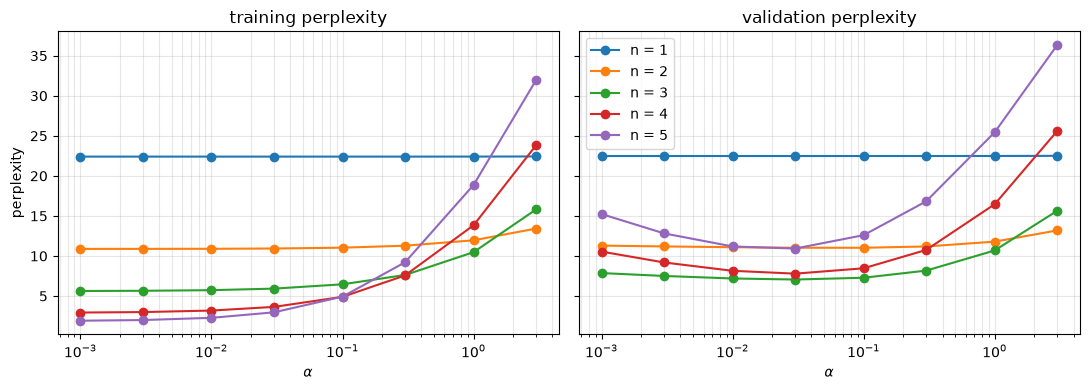

 n  best alpha  train PPL  val PPL  contexts seen  possible
 1       0.001      22.40    22.48              1         1
 2         0.1      11.03    11.02             62        62
 3        0.03       5.92     7.06            703      3844
 4        0.03       3.64     7.79           3226    238328
 5        0.03       2.96    10.92           7164  14776336


In [65]:
# Question: how far does a longer context help a count-based character model, and when does it start to overfit?
# Add-alpha n-gram models (context = previous n-1 characters), same train/val split as in Task 2.3.

def ngram_perplexities(n, alpha):
    """Training PPL, validation PPL and number of distinct training contexts of the add-alpha n-gram model."""
    ctx = torch.zeros(len(ids), dtype=torch.long)
    for k in range(n - 1):                              # encode the context as one integer in base V
        ctx = ctx * V + torch.roll(ids, n - 1 - k)
    ctx, nxt = ctx[n - 1:], ids[n - 1:]                 # entry j predicts character j + n - 1
    keys = ctx * V + nxt                                # (context, next) as one integer
    train_part = slice(0, n_train - (n - 1))            # context and target inside the training text
    val_part = slice(n_train, None)                     # context and target inside the validation text

    # V^n can be huge, so count only the combinations that occur (sorted unique keys)
    pair_keys, pair_count = torch.unique(keys[train_part], return_counts=True)
    ctx_keys, ctx_count = torch.unique(ctx[train_part], return_counts=True)

    def lookup(sorted_keys, values, query):             # count of `query`, 0 if never seen
        pos = torch.searchsorted(sorted_keys, query).clamp(max=len(sorted_keys) - 1)
        return torch.where(sorted_keys[pos] == query, values[pos], 0).double()

    result = []
    for part in (train_part, val_part):
        p = (lookup(pair_keys, pair_count, keys[part]) + alpha) / (lookup(ctx_keys, ctx_count, ctx[part]) + alpha * V)
        result.append(math.exp(-torch.log(p).mean().item()))
    return result[0], result[1], len(ctx_keys)


# n = 2 must reproduce the bigram model of Task 2.3
assert abs(ngram_perplexities(2, 1)[0] - perplexity(bigram_table(1), train_ids)) < 1e-6
assert abs(ngram_perplexities(2, 1)[1] - perplexity(bigram_table(1), val_ids)) < 1e-6

alphas = [0.001, 0.003, 0.01, 0.03, 0.1, 0.3, 1, 3]
table = {n: [ngram_perplexities(n, a) for a in alphas] for n in (1, 2, 3, 4, 5)}

fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for n, rows in table.items():
    line, = axes[0].semilogx(alphas, [r[0] for r in rows], "o-", label=f"n = {n}")
    axes[1].semilogx(alphas, [r[1] for r in rows], "o-", color=line.get_color(), label=f"n = {n}")
for ax, title in zip(axes, ("training perplexity", "validation perplexity")):
    ax.set_xlabel(r"$\alpha$")
    ax.set_title(title)
    ax.grid(alpha=0.3, which="both")
axes[0].set_ylabel("perplexity")
axes[1].legend()
plt.tight_layout()
plt.show()

print(f"{'n':>2s}{'best alpha':>12s}{'train PPL':>11s}{'val PPL':>9s}{'contexts seen':>15s}{'possible':>10s}")
for n, rows in table.items():
    tr, va, n_ctx = min(rows, key=lambda r: r[1])
    best_a = alphas[rows.index((tr, va, n_ctx))]
    print(f"{n:>2d}{best_a:>12}{tr:11.2f}{va:9.2f}{n_ctx:>15d}{V ** (n - 1):>10d}")

**Question: how much does a longer context help a count-based character model, and when does it start to overfit?** I generalised the bigram model to add-$\alpha$ $n$-grams (the context is the previous $n-1$ characters; $n = 2$ reproduces Task 2.3 exactly) and scanned $\alpha$ for $n = 1, \dots, 5$. Going from bigrams to **trigrams** lowers the best validation perplexity from 11.0 to 7.1, because two characters already pin down much of a word's spelling. Beyond that the gain disappears: 4-grams are slightly worse (7.8) and 5-grams much worse (10.9, nearly back to the bigram level), although their *training* perplexity keeps falling (5.9 → 3.6 → 3.0). The reason is data sparsity: the number of possible contexts grows as $V^{n-1}$ (14.8 million for $n = 5$), the 18k training characters contain only about 7k distinct 4-character contexts, each seen only a few times, and many validation contexts never occur in training at all, so the model has to fall back on the smoothing, i.e. on the uniform distribution. The growing gap between training and validation perplexity is overfitting; the best $\alpha$ also becomes smaller for longer contexts (0.1 for bigrams, 0.03 for $n \ge 3$), because with sparse counts every pseudo-count is a large share of a row. A neural model that shares parameters between similar contexts (as the transformers later in the course do) avoids this explosion of the table.